In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from ipywidgets import interact

plt.rcParams['figure.figsize'] = (11, 5)

In [4]:
movies = pd.read_csv('tmdb-movies.csv')
movies.head()
movies = movies.drop_duplicates()

for col in ['budget_adj', 'revenue_adj', 'runtime']:
    movies[col] = movies[col].replace(0, np.nan)

movies['decade'] = movies['release_year'] // 10 * 10
movies['profit'] = movies['revenue_adj'] - movies['budget_adj']
movies['runtime_bin'] = pd.cut(movies['runtime'], bins=[0, 90, 100, 110, 120, 135, 150, 1000],
                               labels=['<90', '90-99', '100-109', '110-119', '120-134', '135-149', '150+'])

genres = (movies.dropna(subset=['genres'])
          .assign(genre=lambda d: d['genres'].str.split('|'))
          .explode('genre'))

movies.head()

,id,imdb_id,popularity,budget,revenue,original_title,cast,homepage,director,tagline,...,production_companies,release_date,vote_count,vote_average,release_year,budget_adj,revenue_adj,decade,profit,runtime_bin
0,135397,tt0369610,32.985763,150000000,1513528810,Jurassic World,Chris Pratt|Bryce Dallas Howard|Irrfan Khan|Vi...,http://www.jurassicworld.com/,Colin Trevorrow,The park is open.,...,Universal Studios|Amblin Entertainment|Legenda...,6/9/15,5562,6.5,2015,1.379999e+08,1.392446e+09,2010,1.254446e+09,120-134
1,76341,tt1392190,28.419936,150000000,378436354,Mad Max: Fury Road,Tom Hardy|Charlize Theron|Hugh Keays-Byrne|Nic...,http://www.madmaxmovie.com/,George Miller,What a Lovely Day.,...,Village Roadshow Pictures|Kennedy Miller Produ...,5/13/15,6185,7.1,2015,1.379999e+08,3.481613e+08,2010,2.101614e+08,110-119
2,262500,tt2908446,13.112507,110000000,295238201,Insurgent,Shailene Woodley|Theo James|Kate Winslet|Ansel...,http://www.thedivergentseries.movie/#insurgent,Robert Schwentke,One Choice Can Destroy You,...,Summit Entertainment|Mandeville Films|Red Wago...,3/18/15,2480,6.3,2015,1.012000e+08,2.716190e+08,2010,1.704191e+08,110-119
3,140607,tt2488496,11.173104,200000000,2068178225,Star Wars: The Force Awakens,Harrison Ford|Mark Hamill|Carrie Fisher|Adam D...,http://www.starwars.com/films/star-wars-episod...,J.J. Abrams,Every generation has a story.,...,Lucasfilm|Truenorth Productions|Bad Robot,12/15/15,5292,7.5,2015,1.839999e+08,1.902723e+09,2010,1.718723e+09,135-149
4,168259,tt2820852,9.335014,190000000,1506249360,Furious 7,Vin Diesel|Paul Walker|Jason Statham|Michelle ...,http://www.furious7.com/,James Wan,Vengeance Hits Home,...,Universal Pictures|Original Film|Media Rights ...,4/1/15,2947,7.3,2015,1.747999e+08,1.385749e+09,2010,1.210949e+09,135-149


# Question 1: How has the movie industry's output and commercial performances changed over time?
## TASK 1A
### How have the number of releases and the average revenue per film changed by year?

In [6]:
def releases_and_revenue(year_range):
    d = movies[movies['release_year'].between(*year_range)]
    yearly = d.groupby('release_year').agg(n_films=('id', 'count'),
                                           mean_revenue=('revenue_adj', 'mean'))
    fig, ax = plt.subplots()
    ax.plot(yearly.index, yearly['n_films'], color='tab:blue', label='Number of releases')
    ax.set_xlabel('Release year')
    ax.set_ylabel('Number of releases', color = 'tab:blue')
    ax2 = ax.twinx()
    ax2.plot(yearly.index, yearly['mean_revenue'] / 1e6, color = 'tab:orange', label = 'Mean Revenue')
    ax2.set_ylabel('Mean revenue per film ($M, 2010)', color = 'tab:orange')
    r_n = yearly.reset_index().corr().loc['release_year', 'n_films']
    r_rev = yearly.reset_index().corr().loc['release_year', 'mean_revenue']
    ax.set_title(f'Releases and mean revenue by year (r with year: releases = {r_n:.2f}, revenue = {r_rev:.2f})')
    plt.show()

interact(releases_and_revenue, year_range=widgets.IntRangeSlider(value=(1960, 2015), min=1960,
                                                                max=2015, description='Years'))

interactive(children=(IntRangeSlider(value=(1960, 2015), description='Years', max=2015, min=1960), Output()), …

<function __main__.releases_and_revenue(year_range)>

## TASK 1B
### Which years or decades had unusually high or low total box-office revenue?

In [7]:
def revenue_extremes(level, measure):
    grouped = movies.groupby(level)['revenue_adj']
    s = grouped.sum() if measure == 'Total' else grouped.mean()
    z = (s - s.mean()) / s.std()
    colors = ['tab:red' if v > 1.5 else 'tab:purple' if v < -1.5 else 'lightgray' for v in z]
    
    fig, ax = plt.subplots()
    ax.bar(s.index.astype(str), s / 1e9 if measure == 'Total' else s / 1e6, color = colors)
    ax.set_ylabel('Total revenue ($B, 2010)' if measure == 'Total' else 'Mean revenue per film ($M, 2010)')
    ax.set_title(f'{measure} box-office revenye by {level} (red = unusually high, purple = unusually low, |z| > 1.5)')
    if level == 'release_year':
        ax.set_xticks(ax.get_xticks()[::5])
    plt.show()
    print('Highest:', s.nlargest(3).index.tolist(), ' Lowest:', s.nsmallest(3).index.tolist())

interact(revenue_extremes, level=widgets.Dropdown(options=['release_year', 'decade'], description = 'Group By'),
         measure=widgets.ToggleButtons(options=['Total', 'Per film'], description='Measure'))

interactive(children=(Dropdown(description='Group By', options=('release_year', 'decade'), value='release_year…

<function __main__.revenue_extremes(level, measure)>

# Question 2: How does a movie's runtime correlate with viewership and score?
## TASK 2A
### Do longer runtimes correlate with lower viewership?

In [11]:
def runtime_vs_viewership(metric, runtime_range):
    d = movies[movies['runtime'].between(*runtime_range)].dropna(subset=['runtime', metric])
    trend = d.groupby('runtime_bin', observed=True).agg(runtime=('runtime', 'median'), value = (metric, 'median'))
    fig, ax = plt.subplots()
    ax.scatter(d['runtime'], d[metric], alpha = 0.25, s=10)
    ax.plot(trend['runtime'], trend['value'], color='black', marker = 'o', label = 'median per runtime bin')
    ax.set_yscale('log')
    ax.set_xlabel('runtime (minutes)')
    ax.set_ylabel(metric)
    rho = d['runtime'].corr(d[metric], method='spearman')
    ax.set_title(f'Runtime vs {metric} (Spearman correlation = {rho:.2f}, n = {len(d)})')
    ax.legend()
    plt.show()

interact(runtime_vs_viewership, metric=widgets.Dropdown(options=['popularity', 'revenue_adj'], description = 'metric'),
         runtime_range=widgets.IntRangeSlider(value=(60, 200), min = 1, max = 900, description = 'runtime'))


interactive(children=(Dropdown(description='metric', options=('popularity', 'revenue_adj'), value='popularity'…

<function __main__.runtime_vs_viewership(metric, runtime_range)>

## TASK 2B
### Do longer runtimes correlate with higher scores?

In [ ]:
def runtime_vs_score(min_votes):
    d = movies[movies['vote_count'] >= min_votes].dropna(subset=['runtime_bin'])
    bins = d['runtime_bin'].cat.categories
    data = [d.loc[d['runtime_bin'] == b, 'vote_average'] for b in bins]
    fig, ax = plt.subplots()
    ax.boxplot(data, tick_labels=bins)
    ax.plot(range(1, len(bins) + 1), [x.mean() for x in data], color = 'tab:red', marker='D', label='mean')
    ax.set_xlabel('runtime (minutes)')
    ax.set_ylabel('vote average')
    rho = d['runtime'].corr(d['vote_average'], method='spearman')
    ax.set_title(f'Score by runtime (Spearman correlation = {rho:.2f}, n = {len(d)})')
    ax.legend()
    plt.show()

interact(runtime_vs_score, min_votes=widgets.IntSlider(value=10, min=10, max=1000, step=10, description='min votes'))

interactive(children=(IntSlider(value=10, description='min votes', max=1000, min=10, step=10), Output()), _dom…

<function __main__.runtime_vs_score(min_votes)>

# Question 3: How do genres differ in profitability and audience reception?
## TASK 3A
### How are average ratings spread within each genre, and which genres vary most?

In [ ]:
def genre_rating_spread(min_votes):
    d = genres[genres['vote_count'] >= min_votes]
    order = d.groupby('genre')['vote_average'].median().sort_values().index
    fig, ax = plt.subplots(figsize=(11, 7))
    ax.boxplot([d.loc[d['genre'] == g, 'vote_average'] for g in order], tick_labels=order, vert=False)
    ax.set_xlabel('vote average')
    ax.set_title('vote average by genre (sorted by median)')
    plt.show()
    spread = d.groupby('genre')['vote_average'].agg(n='count', median='median', std='std', IQR=lambda x: x.quantile(0.75) - x.quantile(0.25))
    display(spread.sort_values('std', ascending=False).round(2))

interact(genre_rating_spread, min_votes = widgets.IntSlider(value=10, min=10, max=1000, step=10, description='min votes'))

interactive(children=(IntSlider(value=10, description='min votes', max=1000, min=10, step=10), Output()), _dom…

<function __main__.genre_rating_spread(min_votes)>

## TASK 3B
### Which genres earn the most median profit, and has that ranking shifted across decades?

In [16]:
profit_genres = genres.dropna(subset=['profit'])
median_profit = profit_genres.pivot_table(index='genre', columns='decade', values='profit', aggfunc='median')
film_counts = profit_genres.pivot_table(index='genre', columns='decade', values='profit', aggfunc='count')
median_profit = median_profit.where(film_counts >= 5)

def genre_profit(decade):
    s = median_profit[decade].dropna().sort_values()
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.barh(s.index, s / 1e6)
    ax.set_xlabel('Median profit per film ($M, 2010)')
    ax.set_title(f'Median profit by genre, {decade}s (genres with 5+ films)')
    plt.show()

interact(genre_profit, decade=widgets.Dropdown(options=list(median_profit.columns), value=2010, description='decade'))


interactive(children=(Dropdown(description='decade', index=5, options=(1960, 1970, 1980, 1990, 2000, 2010), va…

<function __main__.genre_profit(decade)>

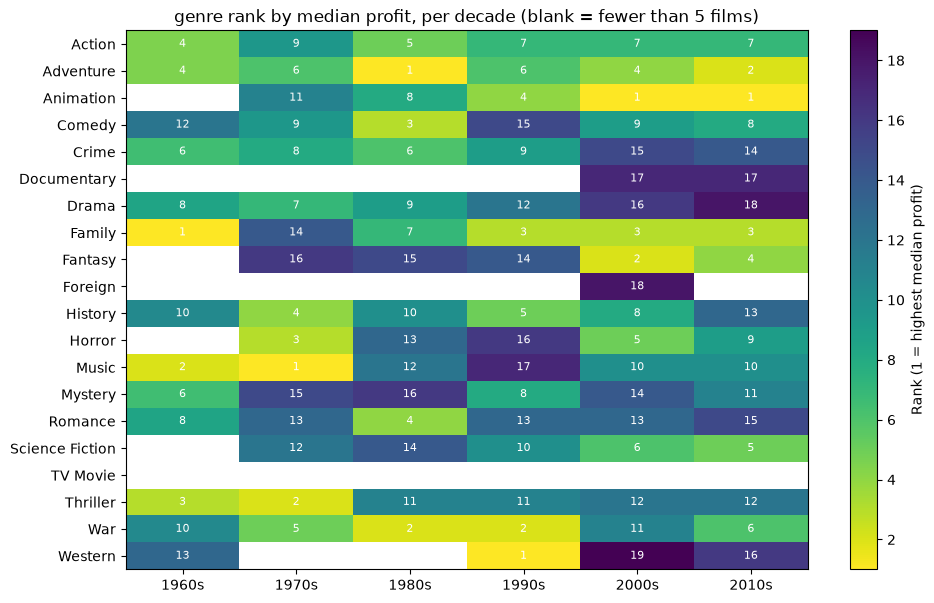

In [20]:
ranks = median_profit.rank(ascending=False)
fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(ranks, cmap='viridis_r', aspect='auto')
ax.set_xticks(range(len(ranks.columns)), [f'{c}s' for c in ranks.columns])
ax.set_yticks(range(len(ranks.index)), ranks.index)
for i in range(ranks.shape[0]):
    for j in range(ranks.shape[1]):
        if not np.isnan(ranks.iat[i, j]):
            ax.text(j, i, int(ranks.iat[i, j]), ha='center', va='center', color='white', fontsize=8)
fig.colorbar(im, label='Rank (1 = highest median profit)')
ax.set_title('genre rank by median profit, per decade (blank = fewer than 5 films)')
plt.show()


# Question 4: What factors are associated with a movie's critical success, and is critical success tied to commercial success?
## TASK 4A
### Which genres and directors tend to get the highest audience ratings?

In [25]:
def top_rated(group_by, top_n, min_votes):
    if group_by == 'genre':
        d = genres
    elif group_by == 'director':
        d = movies.groupby('director').filter(lambda g: len(g) >= 5)
    else:
        d = movies
    d = d[d['vote_count'] >= min_votes]
    s = d.groupby(group_by, observed=True)['vote_average'].mean().nlargest(top_n).sort_values()
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.barh(s.index.astype(str), s)
    ax.set_xlim(s.min() - 0.5, s.max() +0.2)
    ax.set_xlabel('mean vote average')
    ax.set_title(f'top {top_n} by mean vote average, grouped by {group_by}'
             + ('    (directors with 5+ films)' if group_by == 'director' else ''))
    plt.show()

interact(top_rated, group_by=widgets.Dropdown(options=['genre', 'runtime_bin', 'director'], description='group by'),
         top_n=widgets.IntSlider(value=10, min=3, max=20, description='top n'),
         min_votes=widgets.IntSlider(value=50, min=10, max=1000, step=10, description='min votes'))

interactive(children=(Dropdown(description='group by', options=('genre', 'runtime_bin', 'director'), value='ge…

<function __main__.top_rated(group_by, top_n, min_votes)>

## TASK 4B
### Do highly rated movies also make more money, and has that relationship changed over time?

In [29]:
rated = movies.dropna(subset=['revenue_adj']).copy()
rated['log_revenue'] = np.log10(rated['revenue_adj'])
slope, intercept = np.polyfit(rated['vote_average'], rated['log_revenue'], 1)
rated['residual'] = rated['log_revenue'] - (slope * rated['vote_average'] + intercept)

def rating_vs_revenue(decade, n_labels):
    d = rated if decade == 'All' else rated[rated['decade'] == decade]
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.scatter(d['vote_average'], d['revenue_adj'], alpha=0.25, s=10)
    x = np.linspace(d['vote_average'].min(), d['vote_average'].max(), 50)
    ax.plot(x, 10 ** (slope * x + intercept), color='black', label='Trend (all years)')
    outliers = d.loc[d['residual'].abs().nlargest(n_labels).index]
    ax.scatter(outliers['vote_average'], outliers['revenue_adj'], color='tab:red', s=25)
    for _, row in outliers.iterrows():
        ax.annotate(row['original_title'], (row['vote_average'], row['revenue_adj']), fontsize=8)
    ax.set_yscale('log')
    ax.set_xlabel('Vote average')
    ax.set_ylabel('Revenue ($, 2010, log scale)')
    r = d['vote_average'].corr(d['log_revenue'])
    ax.set_title(f'Rating vs revenue, {decade}  (r = {r:.2f}, n = {len(d)})')
    ax.legend()
    plt.show()

interact(rating_vs_revenue,
         decade=widgets.Dropdown(options=['All'] + sorted(rated['decade'].unique().tolist()), description='Decade'),
         n_labels=widgets.IntSlider(value=8, min=0, max=20, description='Label top'))

interactive(children=(Dropdown(description='Decade', options=('All', 1960, 1970, 1980, 1990, 2000, 2010), valu…

<function __main__.rating_vs_revenue(decade, n_labels)>

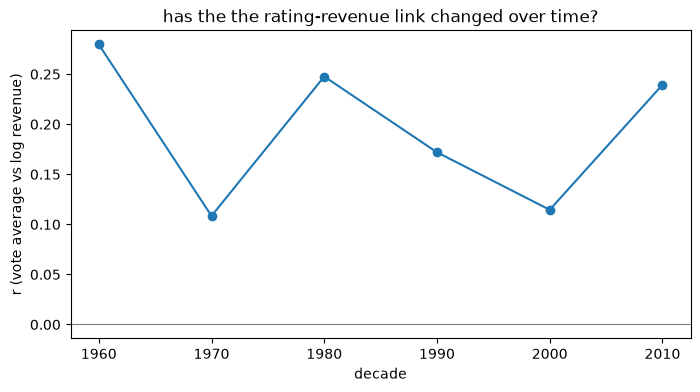

In [31]:
by_decade = rated.groupby('decade').apply(lambda g: g['vote_average'].corr(g['log_revenue']))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(by_decade.index, by_decade, marker='o')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_xlabel('decade')
ax.set_ylabel('r (vote average vs log revenue)')
ax.set_title('has the the rating-revenue link changed over time?')
plt.show()